# `geopandas`

Learn how to work with vector data using the `geopandas` Python package, and make our first maps, by examining wild pig (*Sus scrofa*) occurrence records in California.

See more information about the data on the [course website](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-10-geopandas-intro/lesson-10-geopandas-intro.html).

## Learning objectives

By the end of this lesson, students will be able to:

- Read a shapefile into a `geopandas.GeoDataFrame`.
- Describe how a `geopandas.GeoDataFrame` relates to its geometry column, a `geopandas.GeoSeries`.
- Inspect the geometry types, CRS and extent of a `geopandas.GeoDataFrame`.
- Explore point data on an interactive map with `explore()`.
- Create a map with several layers using `matplotlib`'s `fig` and `ax`.

## About the data

Wild pigs (*Sus scrofa*) are a destructive invasive species in California, causing significant environmental and agricultural damage. Introduced to the region in the 1700s, they have since spread across the state, impacting native ecosystems through habitat destruction, soil disturbance due to their rooting behavior, and competition with native wildlife for food.

We will use **simplified** point data about wild pig occurrence records in California from the [Global Biodiversity Information Facility (GBIF)](https://www.gbif.org), an international network and data platform that provides open access to biodiversity data from museums, research institutions and citizen science platforms like iNaturalist. This data is shared under a [CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/) license. Each row is one occurrence record. The column names were shortened to fit the 10-character limit of shapefile column names:

| Column | Description |
|--------|-------------|
| `gbifID` | Unique identifier of the record in GBIF. The full record is at `https://www.gbif.org/occurrence/` followed by this ID. |
| `species` | Scientific name of the species |
| `state` | State where the record was made |
| `individual` | Number of individuals recorded |
| `day`, `month`, `year` | Date of the record |
| `inst` | Code of the institution that provided the record, for example a museum or a citizen science platform |
| `collection` | Code of the collection within that institution |
| `catalogNum` | Identifier of the record in the institution's catalog |
| `identified` | Person or institution who identified the species |
| `geometry` | Location of the record |

We will also use a shapefile with the boundary of the state of California from the US Census Bureau's 2016 TIGER/Line shapefiles, which has a single feature: the outline of the state.

Download the `gbif_sus_scrofa_california` and `ca_state_boundary` folders from the course's [shared data folder](https://drive.google.com/drive/folders/1USqhiMLyN8GE05B8WJmHabviJGnmAsLP?usp=sharing) and save them in a `data/` folder next to your notebook.

## `geopandas`

`geopandas` extends `pandas` to work with geospatial data. This is the main package we will be working with in the next few lessons.

Let's start by importing the necessary packages and our data:

In [1]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
# UPDATE THESE FILE PATHS TO POINT TO YOUR DATA IF NECESSARY
fp = os.path.join('data','gbif_sus_scrofa_california','gbif_sus_scrofa_california.shp')
pigs = gpd.read_file(fp)
pigs.head()

,gbifID,species,state,individual,day,month,year,inst,collection,catalogNum,identified,geometry
0,899953814,Sus scrofa,California,NaN,22.0,3.0,2014.0,iNaturalist,Observations,581956,edwardrooks,POINT (-121.53812 37.08846)
1,899951348,Sus scrofa,California,NaN,9.0,6.0,2007.0,iNaturalist,Observations,576047,Bruce Freeman,POINT (-120.54942 35.47354)
2,896560733,Sus scrofa,California,NaN,20.0,12.0,1937.0,MVZ,Hild,MVZ:Hild:195,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.27063 37.87610)
3,896559958,Sus scrofa,California,NaN,1.0,4.0,1969.0,MVZ,Hild,MVZ:Hild:1213,"Museum of Vertebrate Zoology, University of Ca...",POINT (-121.82297 38.44543)
4,896559722,Sus scrofa,California,NaN,1.0,1.0,1961.0,MVZ,Hild,MVZ:Hild:1004,"Museum of Vertebrate Zoology, University of Ca...",POINT (-121.74559 38.54882)


In [3]:
# UPDATE THESE FILE PATHS TO POINT TO YOUR DATA IF NECESSARY
fp = os.path.join('data','ca_state_boundary','ca_state_boundary.shp')
ca_boundary = gpd.read_file(fp)
ca_boundary

,REGION,DIVISION,STATEFP,STATENS,GEOID,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,4,9,06,01779778,06,CA,California,00,G4000,A,403501101370,20466718403,+37.1551773,-119.5434183,"MULTIPOLYGON (((-119.63473 33.26545, -119.6363..."


## `GeoSeries` and `GeoDataFrame`

The core data structure in GeoPandas is the `geopandas.GeoDataFrame`. We can think of it as a `pandas.DataFrame` with a dedicated geometry column that can perform spatial operations.

The **geometry column** in a `geopandas.GeoDataFrame` holds the geometry (point, polygon, etc.) of each spatial feature. This geometry column is of type `geopandas.GeoSeries`. Columns in the `geopandas.GeoDataFrame` with attributes about the features are `pandas.Series` like in a regular `pandas.DataFrame`.

#### Example

First, notice that the rightmost column of the `pigs` geo-dataframe is a column named `geometry` whose values indicate points:

In [4]:
pigs.head(3)

,gbifID,species,state,individual,day,month,year,inst,collection,catalogNum,identified,geometry
0,899953814,Sus scrofa,California,NaN,22.0,3.0,2014.0,iNaturalist,Observations,581956,edwardrooks,POINT (-121.53812 37.08846)
1,899951348,Sus scrofa,California,NaN,9.0,6.0,2007.0,iNaturalist,Observations,576047,Bruce Freeman,POINT (-120.54942 35.47354)
2,896560733,Sus scrofa,California,NaN,20.0,12.0,1937.0,MVZ,Hild,MVZ:Hild:195,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.27063 37.87610)


As usual, we can check the type of our objects using the `type` Python function:

In [5]:
print(type(pigs))
print(type(pigs.geometry)) # geometry is an attribute of the column, not just the column name
print(type(pigs['state']))

<class 'geopandas.geodataframe.GeoDataFrame'>
<class 'geopandas.geoseries.GeoSeries'>
<class 'pandas.core.series.Series'>


The data type of the geometry column is also reflected when we look at the data types of the values in each column:

In [6]:
# Check the data type of each column 
pigs.dtypes

gbifID           int64
species         object
state           object
individual     float64
day            float64
month          float64
year           float64
inst            object
collection      object
catalogNum      object
identified      object
geometry      geometry
dtype: object

We can also check the type of each element in the geometry column using the `geom_type` attribute of a `geopandas.GeoDataFrame`:

In [7]:
pigs.geom_type

0       Point
1       Point
2       Point
3       Point
4       Point
        ...  
1041    Point
1042    Point
1043    Point
1044    Point
1045    Point
Length: 1046, dtype: object

### Check-in

What is the geometry type of the single feature in the California state boundary?

In [8]:
ca_boundary.geom_type

0    MultiPolygon
dtype: object

## CRS

Two other important attributes of a `geopandas.GeoDataFrame` are its coordinate reference system (CRS) and its extent.

We can think of the **coordinate reference system (CRS)** as the instructions to locate each spatial feature of our data frame on the surface of the Earth. We access the CRS of a `geopandas.GeoDataFrame` using the `crs` attribute:

In [9]:
# Access the CRS of the GeoDataFrame
pigs.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

We can obtain more information about our CRS by accessing other attributes:

In [10]:
# Exaimine CRS details 
print('Ellipsoid: ', pigs.crs.ellipsoid)
print('Datum: ', pigs.crs.datum)
print('Is geographic?: ', pigs.crs.is_geographic)
print('Is projected:', pigs.crs.is_projected )

Ellipsoid:  WGS 84
Datum:  World Geodetic System 1984 ensemble
Is geographic?:  True
Is projected: False


## Extent

The **extent** of the geo-dataframe is the bounding box covering *all* the spatial features in our geo-dataframe. This is formed by finding the points that are furthest west, east, south, and north.

We access the extent of a `geopandas.GeoDataFrame` using the `total_bounds` attribute:

In [11]:
# Obtain the geographic extent of the geo-dataframe
# output is in minx, miny, maxx, maxy
pigs.total_bounds

array([-124.29448 ,   32.593433, -115.4356  ,   40.934296])

### Check-in

Print the CRS and extent of the California state boundary.

In [12]:
print('CRS: ', ca_boundary.crs)
print(ca_boundary.total_bounds)

CRS:  EPSG:4326
[-124.48201686   32.52883674 -114.13122248   42.00950827]


## `explore()`

To explore our data interactively, we can use the `explore()` method. This creates an interactive map where we can zoom in and out, move around, and hover over each feature to see its attributes:

In [13]:
pigs.explore()

### Check-in

Zoom into a few points on the map. Each point is drawn as an exact location.

1. Think about how the location of a wild pig record was obtained: an iNaturalist observation taken with a phone today vs. a museum specimen collected in the 1930s. How exact do you think each location is?
2. What extra information about each point would you want to have to use this data to decide whether to close a trail or not?

### Check-in

Records without a geometry are *silently* left out of maps like the one above.

1. Which records do you think are most likely to be missing coordinates? Check your guess with `pigs[pigs.geometry.isna()]`.
2. Describe a situation where these records would still be relevant to an analysis.

In [14]:
pigs[pigs.geometry.isna()]

,gbifID,species,state,individual,day,month,year,inst,collection,catalogNum,identified,geometry
16,857912684,Sus scrofa,California,1.0,14.0,11.0,1987.0,CCBER,Mammals,20340,None,None
17,857912680,Sus scrofa,California,1.0,1.0,9.0,1987.0,CCBER,Mammals,20303,None,None
18,857912673,Sus scrofa,California,1.0,1.0,9.0,1987.0,CCBER,Mammals,20188,None,None
19,857911702,Sus scrofa,California,1.0,29.0,8.0,1987.0,CCBER,Mammals,21909,None,None
20,857911700,Sus scrofa,California,1.0,29.0,8.0,1987.0,CCBER,Mammals,21908,None,None
21,857911692,Sus scrofa,California,1.0,1.0,4.0,1967.0,CCBER,Mammals,3982,None,None
22,857911318,Sus scrofa,California,1.0,1.0,1.0,1973.0,CCBER,Mammals,8601,None,None
23,857911138,Sus scrofa,California,1.0,7.0,2.0,1966.0,CCBER,Mammals,2401,None,None
24,857911129,Sus scrofa,California,1.0,7.0,2.0,1966.0,CCBER,Mammals,2402,None,None
25,857911120,Sus scrofa,California,1.0,NaN,NaN,NaN,CCBER,Mammals,6519,None,None


## Data wrangling

GeoPandas is conveniently built on top of `pandas`, so we may use everything we have learned about data selection, wrangling, and modification for a `pandas.DataFrame` to wrangle `geopandas.GeoDataFrame`s.

#### Example

We only want to use recent data for wild pig observations. Before selecting the data, let's look at which years it covers.

### Check-in

Before running the next cell, write down your prediction: when do you expect the earliest wild pig record in our data to be?

### Check-in

1. Does the earliest year match your prediction? Do you trust it?
2. Run `pigs[pigs['year'] == 1818]`. What do these records have in common?

In [15]:
pigs['year'].value_counts().sort_index()
pigs[pigs['year']==1818]

,gbifID,species,state,individual,day,month,year,inst,collection,catalogNum,identified,geometry
985,1145709929,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140027,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
986,1145709911,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140018,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
987,1145709908,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140016,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
988,1145709904,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140011,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
989,1145709901,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140033,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
990,1145709895,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140028,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
991,1145709889,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140034,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
992,1145709888,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140035,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
993,1145709884,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140031,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)
994,1145709882,Sus scrofa,California,NaN,20.0,6.0,1818.0,MVZ,Mamm,MVZ:Mamm:140024,"Museum of Vertebrate Zoology, University of Ca...",POINT (-122.06866 40.04428)


In this analysis, we will use data from 2020 onwards. We can use our usual data selection to subset it:

In [16]:
pigs_recent = pigs[pigs["year"] >=2020]
print('Total number of observations', len(pigs))
print('Total number of observations since 2020', len(pigs_recent))

Total number of observations 1046
Total number of observations since 2020 606


## Visualizing our data

### `plot()`

Similarly to a `pandas.DataFrame`, a `geopandas.GeoDataFrame` has a `plot()` method that we can call directly to create a quick, static view of our data. The geospatial information of the `geopandas.GeoDataFrame` will be used to create the axes of the plot.

#### Example

Let's take a quick look at our recent pigs data:

In [17]:
pigs_recent.plot()

<Axes: >

### Using `matplotlib`

Going forward, we will make more complex visualizations where we add different layers to a map and customize it. To do this, we will use `matplotlib` via its `pyplot` interface for creating visualizations. You can review the `matplotlib` basics in this [previous lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-18-linear-regression/lesson-18-linear-regression.html).

#### Example

When using matplotlib, it can be useful to think of creating a plot as adding layers to an axes. In this case, the first layer that we want to add to our axes is the `pigs_recent` point data. We can plot our data using `matplotlib` like this:

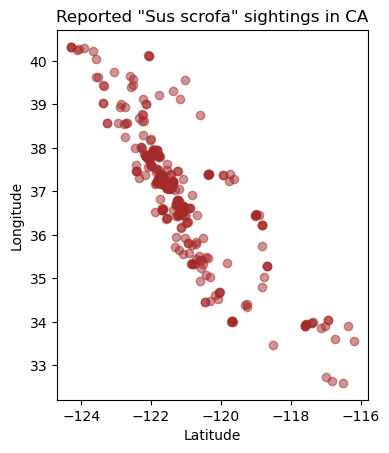

In [20]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add pigs point plot to our figure's aces
pigs_recent.plot(ax=ax,          # Add plot to specific axes
                 alpha = 0.5,    # Control transparency
                 color = 'brown' # Update point color
                 )

# Updata axes
ax.set_title('Reported "Sus scrofa" sightings in CA')
ax.set_xlabel('Latitude')
ax.set_ylabel('Longitude')

# Display figure 
plt.show()

Then some simple customization for our pigs data could look like this:

## Exercises

### Exercise 1

1. Check that both layers have the same CRS using `pigs_recent.crs == ca_boundary.crs`.

2. Add the California state boundary to the plot so the boundary appears behind the points. Don't forget to customize your graph!

3. Write a short caption for your map describing the spatial distribution of observations. What patterns or clusters do you notice?

In [ ]:

print('pigs_recent crs: ', pigs_recent.crs)
print('ca_boundary crs: ', ca_boundary.crs)
print(pigs_recent.crs == ca_boundary.crs)



pigs_recent crs:  EPSG:4326
ca_boundary crs:  EPSG:4326
True


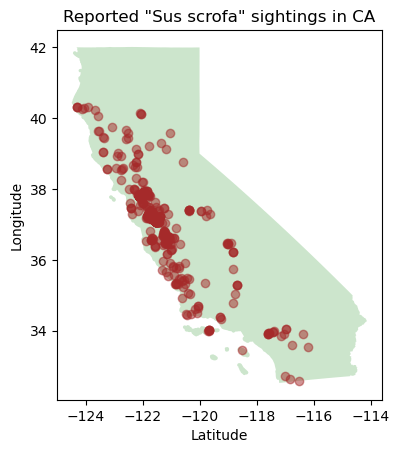

In [ ]:
# Initialize empty figure and axes
fig, ax = plt.subplots()


ca_boundary.plot(ax=ax,
                 alpha=0.2,
                 color = 'green'
                 )
# Add pigs point plot to our figure's aces
pigs_recent.plot(ax=ax,          # Add plot to specific axes
                 alpha = 0.5,    # Control transparency
                 color = 'brown' # Update point color
                 )


# Updata axes
ax.set_title('Reported "Sus scrofa" sightings in CA')
ax.set_xlabel('Latitude')
ax.set_ylabel('Longitude')

# Display figure 
plt.show()

### Exercise 2

A local news site publishes our final map with the headline *"Wild pigs concentrated around the Bay Area"*.

Discuss with a partner:

- Does our map support this headline?
- Who produced the records in our map, and how might that shape where the points are? Perhaps explore the `inst` column.
- Explain what our map can and cannot tell us about where wild pigs are in California. Then suggest a better headline.

In [34]:
pigs['inst'].value_counts()

inst
iNaturalist                                                                     903
MVZ                                                                              61
SBMNH                                                                            21
CAS                                                                              15
CCBER                                                                            13
LACM                                                                              9
HSU                                                                               7
SDNHM                                                                             5
CSULB                                                                             4
UCLA                                                                              4
Borror Laboratory of Bioacoustics, Ohio State University, Columbus, OH (BLB)      2
FMNH                                                                   

The figure suggests that there are a lot of data points appear to be concentrated in the Bay Area. However, it is important to note that a lot of muesum collections such as MVZ in the Bay Area can artificially inflate the distribution of observations of _Sus scrofa_. 